In [1]:
import sys
sys.path.append('..')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, shap
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_curve, precision_recall_curve
from src.features import encode, time_split
from src.model import train_baseline, tune, evaluate, explain_shap, score_customers

data = pd.read_csv('../data/processed/model_dataset.csv', parse_dates=['order_purchase_timestamp'])
enc = encode(data)
DROP = ['customer_unique_id', 'order_purchase_timestamp', 'repeat_180d', 'eligible']

# Only customers who had a full 180 days. Earlier 80% = train, latest 20% = test.
train_df, test_df = time_split(enc[enc['eligible'] == 1], 0.2)
fit_df, cal_df = time_split(train_df, 0.2)   # last slice of train is used only for calibration

def XY(d):
    return d.drop(columns=DROP), d['repeat_180d']

X_fit, y_fit = XY(fit_df); X_cal, y_cal = XY(cal_df); X_test, y_test = XY(test_df)
print(len(X_fit), len(X_cal), len(X_test))
print('repeat rate fit/test:', y_fit.mean().round(4), y_test.mean().round(4))

35779 8945 11181
repeat rate fit/test: 0.0322 0.0337


In [2]:
baseline = train_baseline(X_fit, y_fit)
xgb, best = tune(X_fit, y_fit, n_iter=15)
print(best)
results = pd.DataFrame({'baseline_logreg': evaluate(baseline, X_test, y_test),
                        'xgboost': evaluate(xgb, X_test, y_test)}).round(3)
results

Fitting 3 folds for each of 15 candidates, totalling 45 fits
{'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 10, 'max_depth': 5, 'learning_rate': 0.01, 'colsample_bytree': 0.6}


,baseline_logreg,xgboost
roc_auc,0.579,0.576
pr_auc,0.050,0.050
base_rate,0.034,0.034
precision_in_top_20pct,0.053,0.052
share_of_repeaters_captured_in_top_20pct,0.313,0.308
lift_in_top_20pct,1.565,1.539


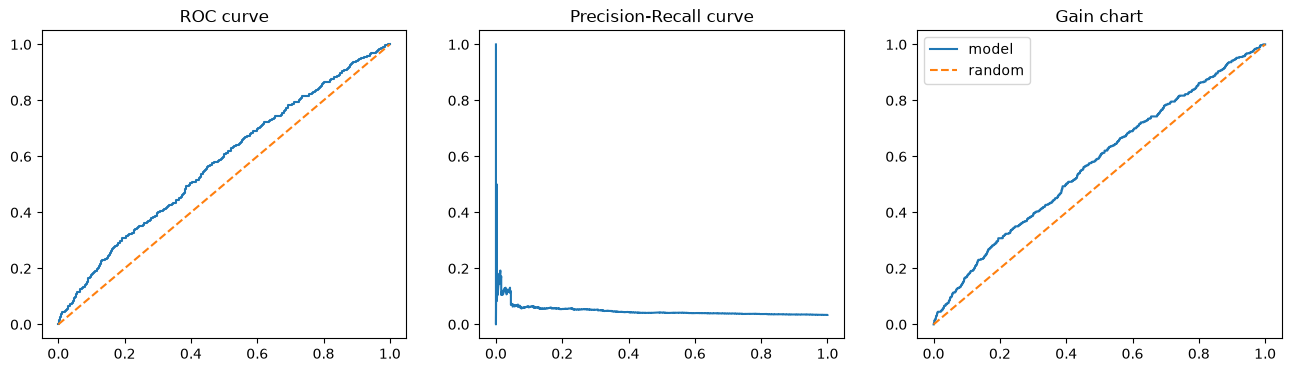

Top 20% of customers capture 30.8 % of repeaters


In [3]:
p_raw = xgb.predict_proba(X_test)[:, 1]
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
fpr, tpr, _ = roc_curve(y_test, p_raw); ax[0].plot(fpr, tpr); ax[0].plot([0, 1], [0, 1], '--'); ax[0].set_title('ROC curve')
pr, rc, _ = precision_recall_curve(y_test, p_raw); ax[1].plot(rc, pr); ax[1].set_title('Precision-Recall curve')
d = pd.DataFrame({'y': y_test.values, 'p': p_raw}).sort_values('p', ascending=False).reset_index(drop=True)
d['captured'] = d['y'].cumsum() / d['y'].sum()
d['pct_customers'] = (d.index + 1) / len(d)
ax[2].plot(d['pct_customers'], d['captured'], label='model'); ax[2].plot([0, 1], [0, 1], '--', label='random')
ax[2].set_title('Gain chart'); ax[2].legend()
plt.savefig('../reports/figures/model_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print('Top 20% of customers capture', round(d.loc[int(len(d) * 0.2) - 1, 'captured'] * 100, 1), '% of repeaters')

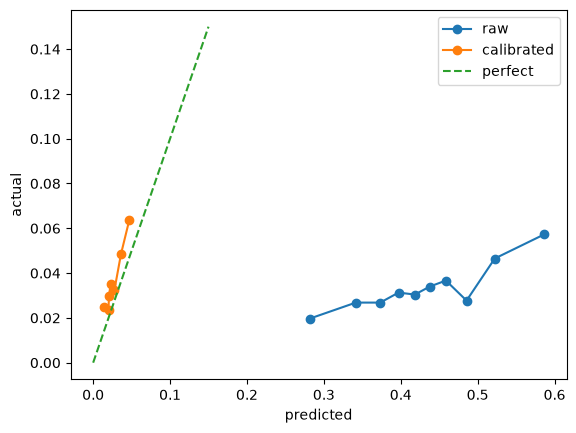

In [4]:
p_cal = xgb.predict_proba(X_cal)[:, 1]
iso = IsotonicRegression(out_of_bounds='clip').fit(p_cal, y_cal)
p_test = iso.predict(p_raw)
for name, p in [('raw', p_raw), ('calibrated', p_test)]:
    frac, mean_pred = calibration_curve(y_test, p, n_bins=10, strategy='quantile')
    plt.plot(mean_pred, frac, marker='o', label=name)
plt.plot([0, 0.15], [0, 0.15], '--', label='perfect'); plt.legend(); plt.xlabel('predicted'); plt.ylabel('actual')
plt.savefig('../reports/figures/calibration.png', dpi=150, bbox_inches='tight')
plt.show()

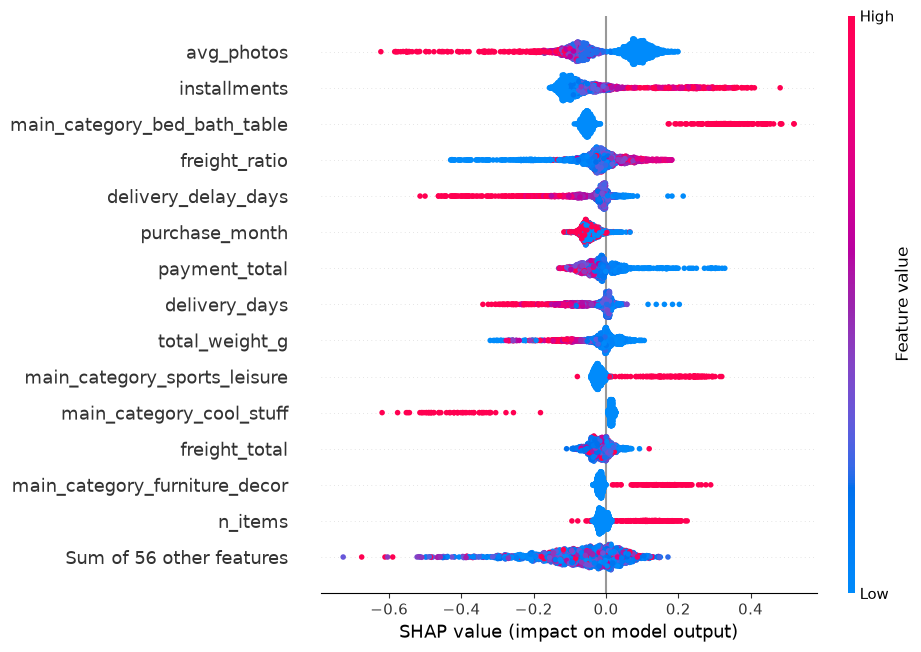

avg_photos                      0.100953
installments                    0.097662
main_category_bed_bath_table    0.077521
freight_ratio                   0.055264
delivery_delay_days             0.047022
dtype: float32


In [5]:
sample = X_test.sample(2000, random_state=1)
sv = explain_shap(xgb, sample)
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.savefig('../reports/figures/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
print(pd.Series(np.abs(sv.values).mean(axis=0), index=sample.columns).sort_values(ascending=False).head(5))

In [6]:
allX = enc.drop(columns=DROP)
scores = score_customers(xgb, allX, iso)
scores['customer_unique_id'] = enc['customer_unique_id'].values
scores['eligible'] = enc['eligible'].values
rfm = pd.read_csv('../data/processed/customer_rfm.csv')
scores = scores.merge(rfm[['customer_unique_id', 'segment']], on='customer_unique_id', how='left')
scores.to_csv('../data/processed/customer_risk_scores.csv', index=False)

# Held-out test customers only: used for the honest money simulation in Chapter 10
pd.DataFrame({'customer_unique_id': test_df['customer_unique_id'].values,
              'repeat_probability': p_test,
              'actual_repeat': y_test.values}).to_csv('../data/processed/test_scores.csv', index=False)